# Test 1 - packet loss with NetEm: analysis

Put this notebook either next to the unpacked `T1` folder, or inside it together with the data files:

```
T1/test1_loss_20261021T1834Z.csv
T1/export_pi5_127.0.0.1.jsonl.gz
T1/export_pi5_netmon-receiver.jsonl.gz
T1/export_vmagent_pi.jsonl.gz
```

Run all cells. Figures are shown here and saved to `figures/` as PDF (for LaTeX) and PNG.
The first 30 s of each step are excluded so that no check overlaps a change of loss level.

In [1]:
%matplotlib inline
import gzip, json, collections, math, os, glob, datetime as dt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Data folder: 'T1' next to the notebook, or the notebook's own folder
DATA = 'T1' if os.path.isdir('T1') else '.'
LOG = sorted(glob.glob(os.path.join(DATA, 'test1_loss_*.csv')))[-1]
print('data folder:', os.path.abspath(DATA)); print('test log   :', LOG)
OUT = 'figures'
os.makedirs(OUT, exist_ok=True)
EXCLUDE_MS = 30_000          # first 30 s of every step left out

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'font.size': 10, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'savefig.dpi': 300, 'figure.dpi': 120})
BLUE, ORANGE, GOOD, CRIT, GRAY = '#2a78d6', '#eb6834', '#0ca30c', '#e34948', '#8a8984'

def save(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(OUT, f'{name}.{ext}'), bbox_inches='tight')

data folder: C:\Users\rich\OneDrive - University of Cape Town\1_FINAL_YEAR\EEE4022S Research Project\T1
test log   : .\test1_loss_20261021T1834Z.csv


## Load the test log and the exported data

In [2]:
def ms(s):
    return dt.datetime.fromisoformat(s.replace('Z', '+00:00')).timestamp() * 1000

# steps: (number, applied loss %, start ms, end ms)
steps = []
for line in open(LOG):
    f = line.strip().split(',')
    if f[0].isdigit():
        steps.append((int(f[0]), int(f[1]), ms(f[2]), ms(f[3])))

def load(fn):
    series = collections.defaultdict(list)
    for line in gzip.open(fn, 'rt'):
        o = json.loads(line)
        series[o['metric']['__name__']].append(o)
    return series

pi = load(os.path.join(DATA, 'export_pi5_127.0.0.1.jsonl.gz'))
vm = load(os.path.join(DATA, 'export_vmagent_pi.jsonl.gz'))

def pts(src, name, s=0, e=float('inf')):
    out = []
    for o in src.get(name, []):
        out += [(t, v) for t, v in zip(o['timestamps'], o['values']) if v is not None and s <= t < e]
    return sorted(out)

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

T0 = steps[0][2]
mins = lambda t: (t - T0) / 60000
steps

[(0, 0, 1792607693000.0, 1792608293000.0),
 (1, 10, 1792608293000.0, 1792608893000.0),
 (2, 30, 1792608893000.0, 1792609493000.0),
 (3, 50, 1792609493000.0, 1792610093000.0),
 (4, 70, 1792610093000.0, 1792610693000.0),
 (5, 90, 1792610693000.0, 1792611293000.0),
 (6, 100, 1792611293000.0, 1792611893000.0),
 (7, 0, 1792611893000.0, 1792612493000.0)]

## Table 1 - results per loss level

In [3]:
from IPython.display import Markdown, display
import csv

rows = []
for n, L, s, e in steps:
    s2 = s + EXCLUDE_MS
    loss = pts(pi, 'ping_loss_pct', s2, e)
    k = sum(round(v / 20) for t, v in loss)          # pings lost (5 per check)
    N = 5 * len(loss)
    lo, hi = wilson(k, N)
    rtt = [v for t, v in pts(pi, 'ping_rtt_ms', s2, e)]
    state = pts(pi, 'monitor_backhaul_state', s2, e)
    snmp = pts(pi, 'snmp_status', s2, e)
    tcp = collections.Counter(v for t, v in pts(pi, 'tcp_status', s2, e))
    rows.append(dict(
        step=n, applied=L, t_start=mins(s), t_end=mins(e),
        checks=len(loss), pings=N,
        measured=k / N * 100, ci_lo=lo * 100, ci_hi=hi * 100,
        rtt=sum(rtt) / len(rtt) if rtt else None,
        all5=sum(1 for t, v in loss if v == 100) / len(loss) * 100,
        down=sum(1 for t, v in state if v == 1) / len(state) * 100,
        tcp_connected=tcp.get(0, 0), tcp_failed=sum(c for v, c in tcp.items() if v >= 2),
        snmp_fail=sum(1 for t, v in snmp if v == 2) / len(snmp) * 100))

# ---- one formatted row per step --------------------------------------------
header = ['Step', 'Time (min)', 'Applied loss', 'Checks', 'Pings', 'Measured loss', '95 % range',
          'Mean RTT (ms)', 'Checks with all 5 lost (%)', 'Time reported down (%)',
          'TCP check: connected / failed', 'SNMP no reply']
names = {0: ' (baseline)', 7: ' (recovery)'}
table = []
for r in rows:
    table.append([
        f"{r['step']}{names.get(r['step'], '')}",
        f"{r['t_start']:.0f}–{r['t_end']:.0f}",
        f"{r['applied']} %",
        f"{r['checks']}",
        f"{r['pings']}",
        f"{r['measured']:.1f} %",
        f"{r['ci_lo']:.1f}–{r['ci_hi']:.1f} %",
        f"{r['rtt']:.1f}" if r['rtt'] else '–',
        f"{r['all5']:.1f} %",
        f"{r['down']:.1f} %",
        f"{r['tcp_connected']} / {r['tcp_failed']}",
        f"{r['snmp_fail']:.1f} %"])

# ---- show it as a real table in the notebook --------------------------------
md = '| ' + ' | '.join(header) + ' |\n'
md += '|' + '|'.join([':---'] + ['---:'] * (len(header) - 1)) + '|\n'
for row in table:
    md += '| ' + ' | '.join(row) + ' |\n'
display(Markdown('**Table 1: Test 1 results per loss level** (first 30 s of each step excluded)\n\n' + md))

# ---- save it for the report -------------------------------------------------
with open(os.path.join(OUT, 't1_results_table.csv'), 'w', newline='') as f:
    csv.writer(f).writerows([header] + table)
print('saved:', os.path.join(OUT, 't1_results_table.csv'))

**Table 1: Test 1 results per loss level** (first 30 s of each step excluded)

| Step | Time (min) | Applied loss | Checks | Pings | Measured loss | 95 % range | Mean RTT (ms) | Checks with all 5 lost (%) | Time reported down (%) | TCP check: connected / failed | SNMP no reply |
|:---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 (baseline) | 0–10 | 0 % | 55 | 275 | 0.4 % | 0.1–2.0 % | 77.5 | 0.0 % | 0.0 % | 0 / 0 | 0.0 % |
| 1 | 10–20 | 10 % | 57 | 285 | 7.4 % | 4.9–11.0 % | 69.7 | 0.0 % | 0.0 % | 0 / 0 | 7.0 % |
| 2 | 20–30 | 30 % | 57 | 285 | 27.0 % | 22.2–32.5 % | 72.4 | 0.0 % | 0.0 % | 0 / 0 | 26.3 % |
| 3 | 30–40 | 50 % | 57 | 285 | 50.2 % | 44.4–55.9 % | 69.4 | 5.3 % | 0.0 % | 3 / 0 | 50.9 % |
| 4 | 40–50 | 70 % | 57 | 285 | 62.8 % | 57.1–68.2 % | 78.3 | 8.8 % | 0.0 % | 3 / 2 | 64.9 % |
| 5 | 50–60 | 90 % | 56 | 280 | 91.1 % | 87.2–93.9 % | 70.1 | 62.5 % | 14.3 % | 14 / 21 | 91.2 % |
| 6 | 60–70 | 100 % | 57 | 285 | 100.0 % | 98.7–100.0 % | – | 100.0 % | 98.2 % | 1 / 57 | 100.0 % |
| 7 (recovery) | 70–80 | 0 % | 57 | 285 | 0.7 % | 0.2–2.5 % | 84.9 | 0.0 % | 0.0 % | 0 / 0 | 0.0 % |


saved: figures\t1_results_table.csv


## Figure 1 - measured against applied loss

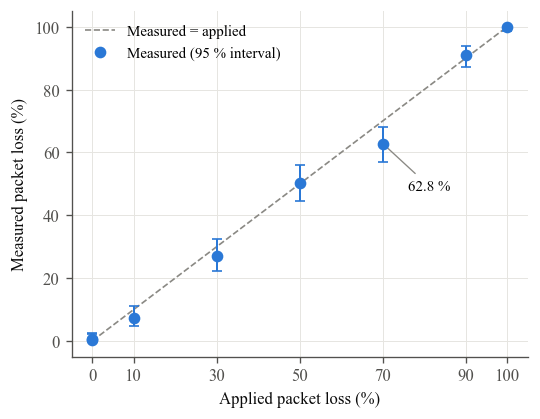

In [16]:
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.plot([0, 100], [0, 100], ls='--', lw=1, color=GRAY, label='Measured = applied')
for r in rows:
    ax.errorbar(r['applied'], r['measured'],
                yerr=[[r['measured'] - r['ci_lo']], [r['ci_hi'] - r['measured']]],
                fmt='o', ms=6, color=BLUE, ecolor=BLUE, elinewidth=1.2, capsize=3, zorder=3)
ax.plot([], [], 'o', color=BLUE, label='Measured (95 % interval)')
r70 = next(r for r in rows if r['applied'] == 70)
ax.annotate(f"{r70['measured']:.1f} %", (70, r70['measured']), xytext=(76, 48), fontsize=9,
            arrowprops=dict(arrowstyle='-', color=GRAY, lw=0.8))
ax.set_xlabel('Applied packet loss (%)'); ax.set_ylabel('Measured packet loss (%)')
ax.set_xlim(-5, 105); ax.set_ylim(-5, 105)
ax.set_xticks([0, 10, 30, 50, 70, 90, 100]); ax.set_yticks(range(0, 101, 20))
ax.legend(frameon=False, loc='upper left', fontsize=9)
fig.tight_layout(); save(fig, 't1_measured_vs_applied'); plt.show()

## Figure 2 - the test as a timeline

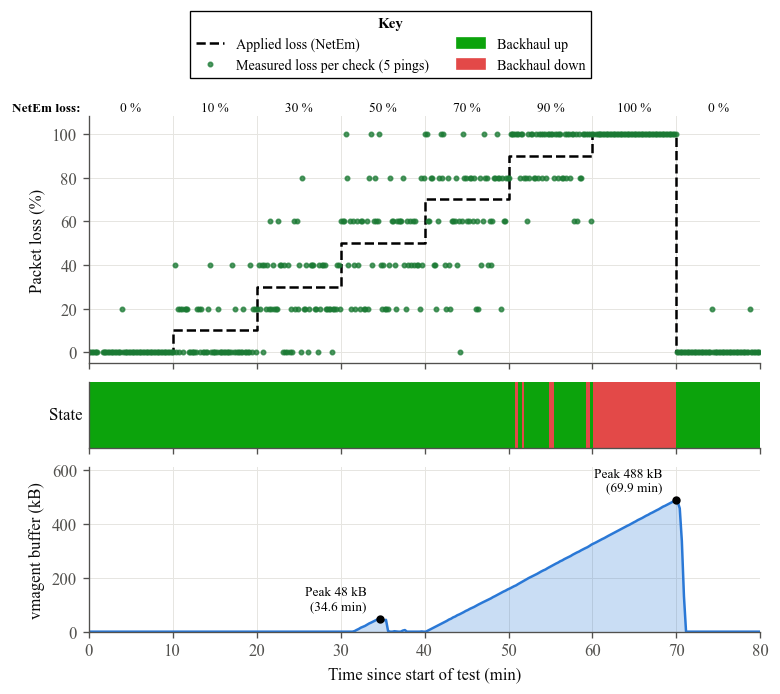

In [19]:
DARK_GREEN, BLACK = '#1b7a34', '#000000'
end = steps[-1][3]
fig, axs = plt.subplots(3, 1, figsize=(6.6, 5.8), sharex=True,
                        gridspec_kw={'height_ratios': [3, 0.8, 2]})
# (a) applied and measured loss
ax_x, ax_y = [], []
for n, L, s, e in steps:
    ax_x += [mins(s), mins(e)]; ax_y += [L, L]
axs[0].plot(ax_x, ax_y, color=BLACK, lw=1.5, ls='--', label='Applied loss (NetEm)')
loss = pts(pi, 'ping_loss_pct', T0, end)
axs[0].plot([mins(t) for t, v in loss], [v for t, v in loss], 'o', ms=2.6, color=DARK_GREEN,
            alpha=0.75, label='Measured loss per check (5 pings)')
axs[0].set_ylabel('Packet loss (%)'); axs[0].set_ylim(-5, 108); axs[0].set_yticks(range(0, 101, 20))
axs[0].text(-1, 1.01, 'NetEm loss:', ha='right', va='bottom', fontsize=8, fontweight='bold',
            color=BLACK, transform=axs[0].get_xaxis_transform())
for n, L, s, e in steps:
    axs[0].text(mins(s) + 5, 1.01, f'{L} %', ha='center', va='bottom', fontsize=8, color=BLACK,
                transform=axs[0].get_xaxis_transform())
# (b) backhaul state
state = pts(pi, 'monitor_backhaul_state', T0, end)
for (t, v), (t2, _) in zip(state, state[1:] + [(end, 0)]):
    axs[1].axvspan(mins(t), mins(t2), color=GOOD if v == 0 else CRIT, lw=0)
axs[1].set_yticks([]); axs[1].grid(False)
axs[1].set_ylabel('State', rotation=0, ha='right', va='center')
# (c) vmagent buffer, with the peak of each period the buffer filled
pend = pts(vm, 'vmagent_remotewrite_pending_data_bytes', T0, end)
px, py = [mins(t) for t, v in pend], [v / 1000 for t, v in pend]
axs[2].fill_between(px, py, color=BLUE, alpha=0.25, lw=0)
axs[2].plot(px, py, color=BLUE, lw=1.5)
peaks, best = [], None
for x, y in zip(px, py):
    if y > 5:                                           # buffer holding data
        if best is None or y > best[1]:
            best = (x, y)
    elif best is not None:
        peaks.append(best); best = None
if best is not None:
    peaks.append(best)
peaks = [(x, y) for x, y in peaks if y > 20]               # ignore tiny blips
for x, y in peaks:
    axs[2].plot(x, y, 'o', ms=4, color=BLACK, zorder=3)
    axs[2].annotate(f'Peak {y:.0f} kB\n({x:.1f} min)', (x, y), xytext=(-8, 4),
                    textcoords='offset points', ha='right', va='bottom', fontsize=8, color=BLACK)
axs[2].set_ylim(0, max(py) * 1.25)
axs[2].set_ylabel('vmagent buffer (kB)'); axs[2].set_xlabel('Time since start of test (min)')
for ax in axs:
    for n, L, s, e in steps[1:]:
        ax.axvline(mins(s), color='#d4d3ce', lw=0.6, zorder=0)
h, l = axs[0].get_legend_handles_labels()
h += [Patch(color=GOOD), Patch(color=CRIT)]; l += ['Backhaul up', 'Backhaul down']
leg = fig.legend(h, l, title='Key', title_fontproperties={'weight': 'bold', 'size': 9},
                 fontsize=8.5, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.0),
                 frameon=True, edgecolor=BLACK, fancybox=False, framealpha=1)
leg.get_frame().set_linewidth(0.8)
axs[2].set_xlim(0, 80); axs[2].set_xticks(range(0, 81, 10))
fig.tight_layout(h_pad=0.6, rect=(0, 0, 1, 0.885)); save(fig, 't1_timeline'); plt.show()

## Figure 3 - predicted against observed fully failed checks

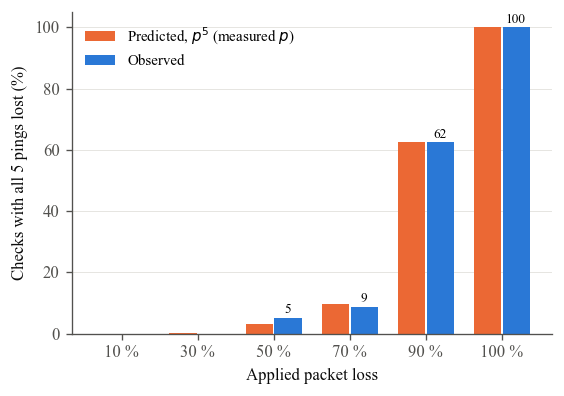

In [22]:
lv = [r for r in rows if r['applied'] > 0]
x = np.arange(len(lv)); w = 0.36
pred = [(r['measured'] / 100) ** 5 * 100 for r in lv]      # all 5 pings lost: p^5
obs = [r['all5'] for r in lv]
fig, ax = plt.subplots(figsize=(4.8, 3.4))
ax.bar(x - w / 2 - 0.01, pred, w, color=ORANGE, label='Predicted, $p^5$ (measured $p$)')
ax.bar(x + w / 2 + 0.01, obs, w, color=BLUE, label='Observed')
for i, b in enumerate(obs):
    if b >= 1:
        ax.text(i + w / 2, b + 1.5, f'{b:.0f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"{r['applied']} %" for r in lv])
ax.set_xlabel('Applied packet loss'); ax.set_ylabel('Checks with all 5 pings lost (%)')
ax.set_ylim(0, 105); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, fontsize=9, loc='upper left')
fig.tight_layout(); save(fig, 't1_predicted_vs_observed'); plt.show()

## Delivery check - monitor against receiver

In [12]:
def unique(fn):
    d = {}
    for line in gzip.open(fn, 'rt'):
        o = json.loads(line)
        key = tuple(sorted(o['metric'].items()))
        d[key] = collections.Counter(zip(o['timestamps'], o['values']))
    return d

A = unique(os.path.join(DATA, 'export_pi5_127.0.0.1.jsonl.gz'))
B = unique(os.path.join(DATA, 'export_pi5_netmon-receiver.jsonl.gz'))
missing = sum(len(set(A[k]) - set(B.get(k, {}))) for k in A)
extra = sum(len(set(B[k]) - set(A.get(k, {}))) for k in B)
dups = sum(c - 1 for cnt in B.values() for c in cnt.values() if c > 1)
print('series   :', len(A), 'on the monitor,', len(B), 'on the receiver')
print('samples  :', sum(sum(c.values()) for c in A.values()), 'on the monitor,',
      sum(sum(c.values()) for c in B.values()), 'on the receiver')
print('missing on receiver:', missing, '| extra on receiver:', extra, '| duplicates:', dups)

series   : 184 on the monitor, 184 on the receiver
samples  : 35423 on the monitor, 35423 on the receiver
missing on receiver: 0 | extra on receiver: 0 | duplicates: 0
